# Experiment 1: Feature Engineering
**Aim:** Handle missing values, encode categorical variables and scale numerical attributes to get a clean, model-ready dataset.

**Dataset:** Titanic passengers (`titanic.csv`): 891 rows × 12 columns. Target column = `Survived` (0 = died, 1 = survived).

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("titanic.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 1: Find missing values

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


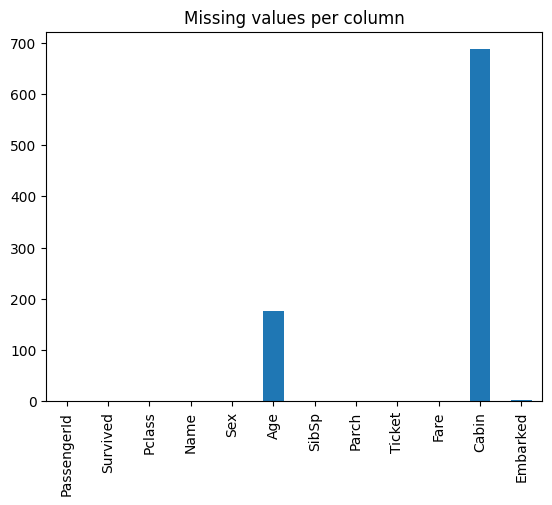

In [4]:
print(df.isnull().sum())

df.isnull().sum().plot(kind="bar", title="Missing values per column")
plt.show()

## Step 2: Handle missing values
- `Cabin` is 77% empty, so drop it
- `Age` is a number, so fill it with the **median**
- `Embarked` is a category, so fill it with the **mode** (most common value)
- `PassengerId`, `Name`, `Ticket` are IDs/text that don't help prediction, so drop them

In [5]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print(df.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## Step 3: Encode categorical variables
- `Sex` has 2 values, so use **Label Encoding** (female = 0, male = 1)
- `Embarked` has 3 values (C, Q, S), so use **One-Hot Encoding** (one 0/1 column per value)

In [6]:
le = LabelEncoder()
df["Sex"] = le.fit_transform(df["Sex"])

df = pd.get_dummies(df, columns=["Embarked"], dtype=int)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,0,1
1,1,1,0,38.0,1,0,71.2833,1,0,0
2,1,3,0,26.0,0,0,7.9250,0,0,1
3,1,1,0,35.0,1,0,53.1000,0,0,1
4,0,3,1,35.0,0,0,8.0500,0,0,1


## Step 4: Scale numerical attributes
`Age` (0–80) and `Fare` (0–512) have very different ranges. **StandardScaler** converts them to mean = 0 and std = 1 using z = (x − mean) / std.

In [7]:
print("Before scaling:")
print(df[["Age", "Fare"]].describe().round(2))

scaler = StandardScaler()
df[["Age", "Fare"]] = scaler.fit_transform(df[["Age", "Fare"]])

print("\nAfter scaling:")
print(df[["Age", "Fare"]].describe().round(2))

Before scaling:
          Age    Fare
count  891.00  891.00
mean    29.36   32.20
std     13.02   49.69
min      0.42    0.00
25%     22.00    7.91
50%     28.00   14.45
75%     35.00   31.00
max     80.00  512.33

After scaling:
          Age    Fare
count  891.00  891.00
mean     0.00    0.00
std      1.00    1.00
min     -2.22   -0.65
25%     -0.57   -0.49
50%     -0.10   -0.36
75%      0.43   -0.02
max      3.89    9.67


## Step 5: Final clean, model-ready dataset

In [8]:
print("Shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print(df.dtypes)

df.to_csv("titanic_clean.csv", index=False)
df.head()

Shape: (891, 10)
Total missing values: 0
Survived        int64
Pclass          int64
Sex             int32
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked_C      int32
Embarked_Q      int32
Embarked_S      int32
dtype: object


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,-0.565736,1,0,-0.502445,0,0,1
1,1,1,0,0.663861,1,0,0.786845,1,0,0
2,1,3,0,-0.258337,0,0,-0.488854,0,0,1
3,1,1,0,0.433312,1,0,0.420730,0,0,1
4,0,3,1,0.433312,0,0,-0.486337,0,0,1


## Step 6: Check that the data is model-ready by training a quick model

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df.drop(columns="Survived")
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Test accuracy:", round(model.score(X_test, y_test), 4))

Test accuracy: 0.8101


## Conclusion
Missing values were dropped (Cabin) or filled (Age with median, Embarked with mode). Text categories were converted to numbers (label encoding for Sex, one-hot encoding for Embarked), and Age/Fare were standardised. The final dataset has **no missing values and only numeric columns**, and a model trains on it directly (≈81% accuracy).